## 主成分分析

```
X1	GDP
X2	人均GDP
X3	工业增加值
X4	第三产业增加值
X5	固定资产投资
X6	基本建设投资
X7	社会消费品零售总额
X8	海关出口总额
X9	地方财政收入
```

## 导入数据

In [1]:
import pandas as pd

In [2]:
#1.导入数据
model_data = pd.read_csv("cities_10.csv",encoding='gbk')
model_data.head()

,AREA,X1,X2,X3,X4,X5,X6,X7,X8,X9
0,辽宁,5458.2,13000,1376.2,2258.4,1315.9,529.0,2258.4,123.7,399.7
1,山东,10550.0,11643,3502.5,3851.0,2288.7,1070.7,3181.9,211.1,610.2
2,河北,6076.6,9047,1406.7,2092.6,1161.6,597.1,1968.3,45.9,302.3
3,天津,2022.6,22068,822.8,960.0,703.7,361.9,941.4,115.7,171.8
4,江苏,10636.3,14397,3536.3,3967.2,2320.0,1141.3,3215.8,384.7,643.7


In [3]:
data = model_data.loc[ :,'X1':]
data.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9
0,5458.2,13000,1376.2,2258.4,1315.9,529.0,2258.4,123.7,399.7
1,10550.0,11643,3502.5,3851.0,2288.7,1070.7,3181.9,211.1,610.2
2,6076.6,9047,1406.7,2092.6,1161.6,597.1,1968.3,45.9,302.3
3,2022.6,22068,822.8,960.0,703.7,361.9,941.4,115.7,171.8
4,10636.3,14397,3536.3,3967.2,2320.0,1141.3,3215.8,384.7,643.7


## 中心标准化

In [4]:
# 3.做主成分之前，进行中心标准化
from sklearn import preprocessing
data = preprocessing.scale(data)

In [5]:
data

array([[-0.37574772, -0.33589708, -0.57070001, -0.33180084, -0.4351153 ,
        -0.68608742, -0.13882664, -0.44958874, -0.36008526],
       [ 1.19924012, -0.48315182,  1.14473196,  0.98455823,  0.79990984,
         0.8650543 ,  0.66401891, -0.27809633,  0.34976628],
       [-0.18446517, -0.76485655, -0.54609356, -0.46884237, -0.63100796,
        -0.49108511, -0.39102534, -0.60224445, -0.68853914],
       [-1.43844228,  0.6481162 , -1.01716572, -1.40498973, -1.21233816,
        -1.16457327, -1.28376177, -0.46528598, -1.12861338],
       [ 1.2259343 , -0.18430174,  1.17200074,  1.08060301,  0.83964698,
         1.06721529,  0.6934899 ,  0.0625339 ,  0.46273553],
       [-0.39102805,  2.66204455,  0.09085021,  0.07932373,  0.3955559 ,
         0.03063913, -0.33286576, -0.06343649,  0.68294126],
       [ 0.3084029 ,  0.05150118,  0.22017521,  0.33489213,  0.80993934,
         1.17974966,  0.39938849, -0.11504119,  0.20374931],
       [-0.61584072, -0.28055447, -0.83620754, -0.66192379, -0

## 计算各主成分解释的变异

In [6]:
# 4.使用sklearn的主成分分析，用于判断保留主成分的数量
from sklearn.decomposition import PCA

``` 
说明：1、第一次的n_components参数应该设的大一点
说明：2、观察explained_variance_ratio_和explained_variance_的取值变化，建议explained_variance_ratio_累积大于0.85,explained_variance_需要保留的最后一个主成分大于0.8，
```

In [7]:
pca = PCA(n_components=9)
pca.fit(data)

PCA(n_components=9)

In [8]:
print(pca.explained_variance_)#解释的方差（对于标准化数据来说，单个主成分解释的方差应该大于1）
print(pca.explained_variance_ratio_)

[8.01129553e+00 1.22149318e+00 6.07923991e-01 9.88894782e-02
 3.86004507e-02 1.51746715e-02 4.88067443e-03 1.33610801e-03
 4.05920593e-04]
[8.01129553e-01 1.22149318e-01 6.07923991e-02 9.88894782e-03
 3.86004507e-03 1.51746715e-03 4.88067443e-04 1.33610801e-04
 4.05920593e-05]


## 选取主成分保留个数

In [9]:
pca = PCA(n_components=2).fit(data)

In [10]:
#特征值
pca.explained_variance_

array([8.01129553, 1.22149318])

## 计算主成分得分

# 因子分析

安装fa_kit  
!pip install fa_kit -i https://pypi.tuna.tsinghua.edu.cn/simple

## 导入数据

In [14]:
# 1.因子分析的概念很多，作为刚入门的人，我们可以认为因子分析是主成分分析的延续
from fa_kit import FactorAnalysis
from fa_kit import plotting as fa_plotting

In [15]:
fa = FactorAnalysis.load_data_samples(
        data,     #标准化以后的数据
        preproc_demean=True,
        preproc_scale=True
        ) 
fa.extract_components()  

## 主成分法

In [16]:
# 2.设定提取主成分的方式。默认为“broken_stick”方法，建议使用“top_n”法
fa.find_comps_to_retain(method='top_n',num_keep=2)

array([0, 1], dtype=int64)

## 最大方差旋转法

In [17]:
# 3.通过最大方差法进行因子旋转
fa.rotate_components(method='varimax')
pd.DataFrame(fa.comps["rot"])#查看因子权重

,0,1
0,0.362880,-0.196047
1,-0.001947,0.943648
2,0.364222,0.006565
3,0.369255,-0.028775
4,0.361258,0.111596
5,0.352799,-0.007144
6,0.370140,-0.118691
7,0.295099,0.061400
8,0.346765,0.199650


## 计算因子得分

In [18]:
# 4.获取因子得分
#以下是矩阵相乘的方式计算因子：因子=原始数据（n*k）*权重矩阵(k*num_keep)  

In [19]:
import numpy as np

In [20]:
fas = pd.DataFrame(fa.comps["rot"])   #因子权重
data = pd.DataFrame(data)#注意data数据需要标准化
fa_score = pd.DataFrame(np.dot(data, fas))

In [21]:
data

,0,1,2,3,4,5,6,7,8
0,-0.375748,-0.335897,-0.570700,-0.331801,-0.435115,-0.686087,-0.138827,-0.449589,-0.360085
1,1.199240,-0.483152,1.144732,0.984558,0.799910,0.865054,0.664019,-0.278096,0.349766
2,-0.184465,-0.764857,-0.546094,-0.468842,-0.631008,-0.491085,-0.391025,-0.602244,-0.688539
3,-1.438442,0.648116,-1.017166,-1.404990,-1.212338,-1.164573,-1.283762,-0.465286,-1.128613
4,1.225934,-0.184302,1.172001,1.080603,0.839647,1.067215,0.693490,0.062534,0.462736
5,-0.391028,2.662045,0.090850,0.079324,0.395556,0.030639,-0.332866,-0.063436,0.682941
6,0.308403,0.051501,0.220175,0.334892,0.809939,1.179750,0.399388,-0.115041,0.203749
7,-0.615841,-0.280554,-0.836208,-0.661924,-0.881238,-1.061488,-0.656177,-0.351481,-0.787682
8,1.576516,-0.115612,1.727300,1.763662,1.732019,1.451493,2.256409,2.925319,2.344095
9,-1.304569,-1.197288,-1.384891,-1.375482,-1.417372,-1.190917,-1.210649,-0.662679,-1.078367


In [22]:
fas

,0,1
0,0.362880,-0.196047
1,-0.001947,0.943648
2,0.364222,0.006565
3,0.369255,-0.028775
4,0.361258,0.111596
5,0.352799,-0.007144
6,0.370140,-0.118691
7,0.295099,0.061400
8,0.346765,0.199650


In [23]:
#因子得分
fa_score

,0,1
0,-1.174241,-0.364178
1,2.095775,-0.654819
2,-1.399899,-0.870629
3,-3.265185,0.698849
4,2.386557,-0.337666
5,0.163901,2.802894
6,1.209012,0.048116
7,-2.084500,-0.322173
8,5.501759,0.105138
9,-3.433179,-1.105531


In [24]:
#因子命名
a=fa_score.rename(columns={0: "Gross", 1: "Avg"})
citi10_fa=model_data.join(a) 

In [25]:
citi10_fa

,AREA,X1,X2,X3,X4,X5,X6,X7,X8,X9,Gross,Avg
0,辽宁,5458.2,13000,1376.2,2258.4,1315.9,529.0,2258.4,123.7,399.7,-1.174241,-0.364178
1,山东,10550.0,11643,3502.5,3851.0,2288.7,1070.7,3181.9,211.1,610.2,2.095775,-0.654819
2,河北,6076.6,9047,1406.7,2092.6,1161.6,597.1,1968.3,45.9,302.3,-1.399899,-0.870629
3,天津,2022.6,22068,822.8,960.0,703.7,361.9,941.4,115.7,171.8,-3.265185,0.698849
4,江苏,10636.3,14397,3536.3,3967.2,2320.0,1141.3,3215.8,384.7,643.7,2.386557,-0.337666
5,上海,5408.8,40627,2196.2,2755.8,1970.2,779.3,2035.2,320.5,709.0,0.163901,2.802894
6,浙江,7670.0,16570,2356.5,3065.0,2296.6,1180.6,2877.5,294.2,566.9,1.209012,0.048116
7,福建,4682.0,13510,1047.1,1859.0,964.5,397.9,1663.3,173.7,272.9,-2.084500,-0.322173
8,广东,11769.7,15030,4224.6,4793.6,3022.9,1275.5,5013.6,1843.7,1201.6,5.501759,0.105138
9,广西,2455.4,5062,367.0,995.7,542.2,352.7,1025.5,15.1,186.7,-3.433179,-1.105531


In [26]:
from pylab import mpl
mpl.rcParams['font.sans-serif'] = ['SimHei'] # 指定默认字体
mpl.rcParams['axes.unicode_minus'] = False # 解决保存图像是负号'-'显示为方块的问题

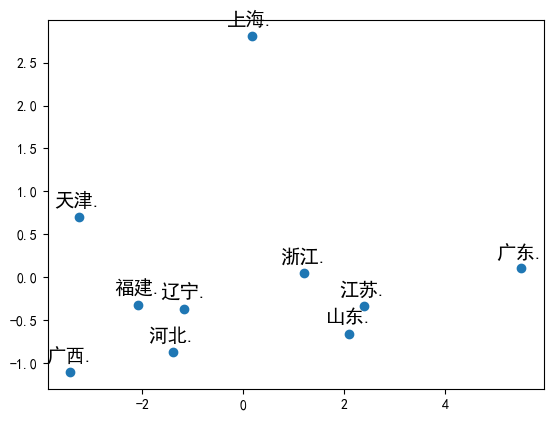

In [27]:
import matplotlib.pyplot as plt
x=citi10_fa['Gross']
y=citi10_fa['Avg']
label=citi10_fa['AREA']
plt.scatter(x, y)
for a,b,l in zip(x,y,label):
    plt.text(a, b+0.1, '%s.' % l, ha='center', va= 'bottom',fontsize=14)

plt.show()